# Lab 01 – Sentiment Analysis Using Traditional Machine Learning
**Module:** PUSL3205 – Large Language Models and Generative AI  
**Student:** HWS Sathsarani **Plymouth ID:** 10967109 | **NSBM ID:** 31270

---

### Objective
To practise basic NLP tasks by building a sentiment classifier that predicts whether a review is **positive (1)** or **negative (0)** using text preprocessing, Bag-of-Words and traditional machine learning models.

### Dataset
[Sentiment Labelled Sentences – UCI Machine Learning Repository](https://archive.ics.uci.edu/dataset/331/sentiment%2Blabelled%2Bsentences)  
3,000 labelled sentences from three sources: **Amazon** (product reviews), **IMDB** (movie reviews) and **Yelp** (restaurant reviews), with 1,000 each and balanced classes.

### Workflow
1. Load the dataset → 2. Preprocess text → 3. Explore the data → 4. Train/test split → 5. Bag-of-Words → 6. Train models (Logistic Regression, SVM) → 7. Evaluate → 8. Test with new sentences

**Libraries:** Pandas, NumPy, NLTK, Scikit-learn, Matplotlib, Seaborn

### 1. Data Loading 

##### 1.1 Importing libraries 

In [4]:
import pandas as pd
import numpy as np
import re
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter

import nltk
from nltk.corpus import stopwords

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.metrics import classification_report, confusion_matrix

nltk.download('stopwords')

sns.set_theme(style='whitegrid', palette='muted')
plt.rcParams['figure.dpi'] = 120

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\senuri\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


##### 1.2 Loading the dataset

In [5]:
amazon = pd.read_csv(r"C:\Users\senuri\Downloads\sentiment+labelled+sentences\sentiment labelled sentences\amazon_cells_labelled.txt",
                     sep='\t', header=None, names=['text', 'label'], quoting=3)

imdb = pd.read_csv(r"C:\Users\senuri\Downloads\sentiment+labelled+sentences\sentiment labelled sentences\imdb_labelled.txt",
                   sep='\t', header=None, names=['text', 'label'], quoting=3)

yelp = pd.read_csv(r"C:\Users\senuri\Downloads\sentiment+labelled+sentences\sentiment labelled sentences\yelp_labelled.txt",
                   sep='\t', header=None, names=['text', 'label'], quoting=3)

amazon['source'] = 'amazon'
imdb['source'] = 'imdb'
yelp['source'] = 'yelp'

df = pd.concat([amazon, imdb, yelp], ignore_index=True)

print(df.shape)
df.head()


(3000, 3)


,text,label,source
0,So there is no way for me to plug it in here i...,0,amazon
1,"Good case, Excellent value.",1,amazon
2,Great for the jawbone.,1,amazon
3,Tied to charger for conversations lasting more...,0,amazon
4,The mic is great.,1,amazon


In [6]:
df['label'].value_counts()

label
0    1500
1    1500
Name: count, dtype: int64

### 2. Text Processing

##### 2.1 Cleaning Function

In [9]:
def clean_text(text):
    text = text.lower()                          # convert to lowercase
    text = re.sub(r'[^a-z\s]', ' ', text)        # remove punctuation, numbers and symbols
    text = re.sub(r'\s+', ' ', text).strip()     # remove extra whitespace
    return text

##### 2.2 Create a clean-text column

In [10]:
df['clean_text'] = df['text'].apply(clean_text)

df[['text', 'clean_text']].head(10)

,text,clean_text
0,So there is no way for me to plug it in here i...,so there is no way for me to plug it in here i...
1,"Good case, Excellent value.",good case excellent value
2,Great for the jawbone.,great for the jawbone
3,Tied to charger for conversations lasting more...,tied to charger for conversations lasting more...
4,The mic is great.,the mic is great
5,I have to jiggle the plug to get it to line up...,i have to jiggle the plug to get it to line up...
6,If you have several dozen or several hundred c...,if you have several dozen or several hundred c...
7,If you are Razr owner...you must have this!,if you are razr owner you must have this
8,"Needless to say, I wasted my money.",needless to say i wasted my money
9,What a waste of money and time!.,what a waste of money and time


##### 2.3 Compare original and preprocessed text

In [11]:
for i in [0, 1500, 2500]:
    print("Original :", df['text'][i])
    print("Cleaned  :", df['clean_text'][i])
    print()

Original : So there is no way for me to plug it in here in the US unless I go by a converter.
Cleaned  : so there is no way for me to plug it in here in the us unless i go by a converter

Original : The entire audience applauded at the conclusion of the film.  
Cleaned  : the entire audience applauded at the conclusion of the film

Original : I also had to taste my Mom's multi-grain pumpkin pancakes with pecan butter and they were amazing, fluffy, and delicious!
Cleaned  : i also had to taste my mom s multi grain pumpkin pancakes with pecan butter and they were amazing fluffy and delicious



### 3. Exploring the text data 

##### 3.1 Label Distribution

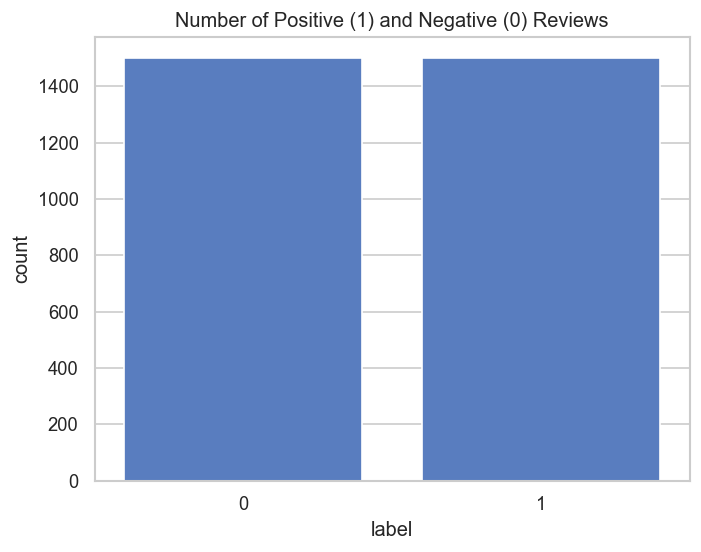

label,0,1
source,,
amazon,500,500
imdb,500,500
yelp,500,500


In [12]:
sns.countplot(x='label', data=df)
plt.title('Number of Positive (1) and Negative (0) Reviews')
plt.show()

df.groupby(['source', 'label']).size().unstack()

##### 3.2 Positive and Negative examples 

In [13]:
print("POSITIVE REVIEWS")
for text in df[df['label'] == 1]['text'].head(5):
    print("-", text)

print("\nNEGATIVE REVIEWS")
for text in df[df['label'] == 0]['text'].head(5):
    print("-", text)

POSITIVE REVIEWS
- Good case, Excellent value.
- Great for the jawbone.
- The mic is great.
- If you are Razr owner...you must have this!
- And the sound quality is great.

NEGATIVE REVIEWS
- So there is no way for me to plug it in here in the US unless I go by a converter.
- Tied to charger for conversations lasting more than 45 minutes.MAJOR PROBLEMS!!
- I have to jiggle the plug to get it to line up right to get decent volume.
- If you have several dozen or several hundred contacts, then imagine the fun of sending each of them one by one.
- Needless to say, I wasted my money.


##### 3.3 Most frequent words

In [15]:
stop_words = set(stopwords.words('english'))

def get_words(texts):
    words = []
    for text in texts:
        for word in text.split():
            if word not in stop_words:
                words.append(word)
    return words

all_words = get_words(df['clean_text'])
Counter(all_words).most_common(20)

[('good', 231),
 ('great', 210),
 ('movie', 182),
 ('phone', 168),
 ('film', 163),
 ('one', 146),
 ('food', 126),
 ('like', 125),
 ('place', 114),
 ('time', 112),
 ('service', 108),
 ('bad', 103),
 ('really', 103),
 ('well', 92),
 ('would', 87),
 ('best', 78),
 ('even', 77),
 ('ever', 76),
 ('also', 74),
 ('back', 73)]

##### 3.4 Positive VS Negative words 

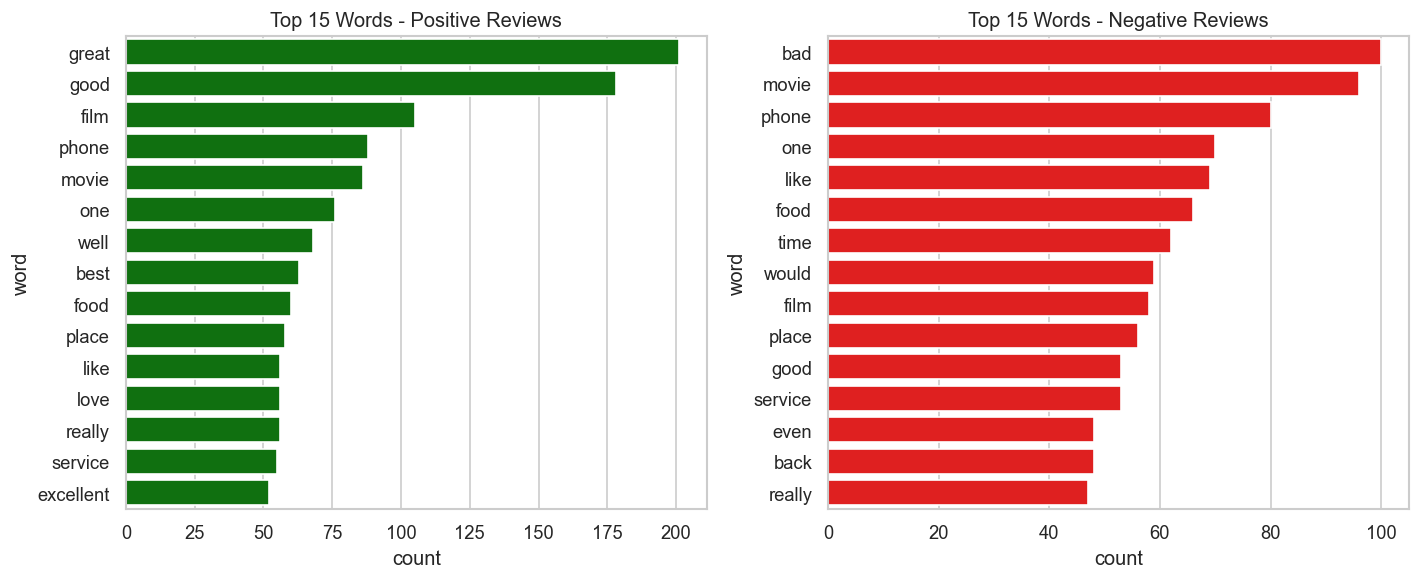

In [16]:
pos_words = Counter(get_words(df[df['label'] == 1]['clean_text'])).most_common(15)
neg_words = Counter(get_words(df[df['label'] == 0]['clean_text'])).most_common(15)

pos_df = pd.DataFrame(pos_words, columns=['word', 'count'])
neg_df = pd.DataFrame(neg_words, columns=['word', 'count'])

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.barplot(x='count', y='word', data=pos_df, ax=axes[0], color='green')
axes[0].set_title('Top 15 Words - Positive Reviews')

sns.barplot(x='count', y='word', data=neg_df, ax=axes[1], color='red')
axes[1].set_title('Top 15 Words - Negative Reviews')

plt.tight_layout()
plt.show()

##### 3.5 Review length comparison

In [17]:
df['word_count'] = df['clean_text'].apply(lambda x: len(x.split()))

df.groupby('label')['word_count'].mean()

label
0    12.128
1    11.960
Name: word_count, dtype: float64

### 4. Splitting data set

In [18]:
X = df['clean_text']
y = df['label']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

print("Training set:", X_train.shape)
print("Testing set :", X_test.shape)

Training set: (2400,)
Testing set : (600,)


### 5.Bag-of-Words Representation

In [19]:
vectorizer = CountVectorizer()

X_train_bow = vectorizer.fit_transform(X_train)
X_test_bow = vectorizer.transform(X_test)

print("Vocabulary size:", len(vectorizer.vocabulary_))
print("Training matrix shape:", X_train_bow.shape)

Vocabulary size: 4479
Training matrix shape: (2400, 4479)


In [20]:
# Example: how one sentence becomes numbers
sample = ["the food was great great"]
sample_bow = vectorizer.transform(sample)

pd.DataFrame(sample_bow.toarray(), columns=vectorizer.get_feature_names_out()).loc[:, lambda d: d.sum() > 0]

,food,great,the,was
0,1,2,1,1


### 6. Training the model

##### 6.1 Logistic Regression

In [22]:
lr_model = LogisticRegression(max_iter=1000)
lr_model.fit(X_train_bow, y_train)

lr_pred = lr_model.predict(X_test_bow)

##### 6.2 Support vector machine

In [23]:
svm_model = LinearSVC()
svm_model.fit(X_train_bow, y_train)

svm_pred = svm_model.predict(X_test_bow)

##### 6.3 Words the model learned 

In [24]:
words = vectorizer.get_feature_names_out()
weights = lr_model.coef_[0]

word_weights = pd.DataFrame({'word': words, 'weight': weights}).sort_values('weight')

print("Top 10 NEGATIVE words:")
print(word_weights.head(10))

print("\nTop 10 POSITIVE words:")
print(word_weights.tail(10))

Top 10 NEGATIVE words:
                word    weight
2929            poor -2.244284
268              bad -2.231539
4430           worst -2.182772
2615             not -1.835545
248            awful -1.700755
3904        terrible -1.618369
1076  disappointment -1.500936
3929            then -1.499087
1075   disappointing -1.424855
3765          stupid -1.401141

Top 10 POSITIVE words:
           word    weight
2586       nice  1.680440
1785    happier  1.686767
1695       good  1.715112
2315      loved  1.738730
990   delicious  1.781631
1348  excellent  1.819951
247     awesome  1.844077
350        best  1.863318
2314       love  2.050772
1719      great  2.939876


### 7. Evaluating the model

##### 7.1 Performance matrix

In [25]:
results = pd.DataFrame({
    'Model': ['Logistic Regression', 'SVM'],
    'Accuracy': [accuracy_score(y_test, lr_pred), accuracy_score(y_test, svm_pred)],
    'Precision': [precision_score(y_test, lr_pred), precision_score(y_test, svm_pred)],
    'Recall': [recall_score(y_test, lr_pred), recall_score(y_test, svm_pred)],
    'F1 Score': [f1_score(y_test, lr_pred), f1_score(y_test, svm_pred)]
})

results.round(3)

,Model,Accuracy,Precision,Recall,F1 Score
0,Logistic Regression,0.822,0.804,0.850,0.827
1,SVM,0.810,0.784,0.857,0.818


##### 7.2 Classification Report

In [26]:
print("Logistic Regression")
print(classification_report(y_test, lr_pred, target_names=['Negative', 'Positive']))

print("SVM")
print(classification_report(y_test, svm_pred, target_names=['Negative', 'Positive']))

Logistic Regression
              precision    recall  f1-score   support

    Negative       0.84      0.79      0.82       300
    Positive       0.80      0.85      0.83       300

    accuracy                           0.82       600
   macro avg       0.82      0.82      0.82       600
weighted avg       0.82      0.82      0.82       600

SVM
              precision    recall  f1-score   support

    Negative       0.84      0.76      0.80       300
    Positive       0.78      0.86      0.82       300

    accuracy                           0.81       600
   macro avg       0.81      0.81      0.81       600
weighted avg       0.81      0.81      0.81       600



##### 7.3 Confusion matrix

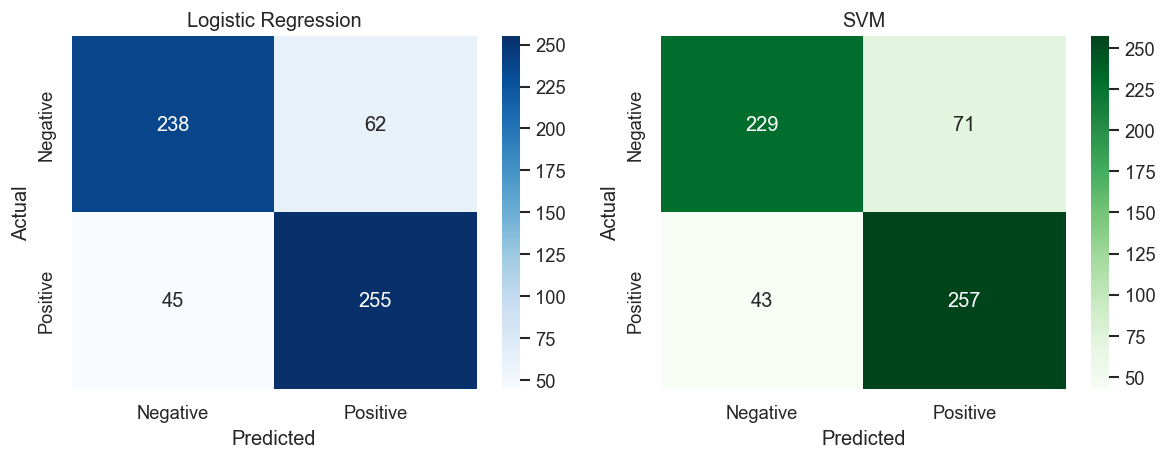

In [28]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

sns.heatmap(confusion_matrix(y_test, lr_pred), annot=True, fmt='d', cmap='Blues',
            xticklabels=['Negative', 'Positive'], yticklabels=['Negative', 'Positive'], ax=axes[0])
axes[0].set_title('Logistic Regression')
axes[0].set_xlabel('Predicted')
axes[0].set_ylabel('Actual')

sns.heatmap(confusion_matrix(y_test, svm_pred), annot=True, fmt='d', cmap='Greens',
            xticklabels=['Negative', 'Positive'], yticklabels=['Negative', 'Positive'], ax=axes[1])
axes[1].set_title('SVM')
axes[1].set_xlabel('Predicted')
axes[1].set_ylabel('Actual')

plt.tight_layout()
plt.show()

### 8. Testing the model with New sentences

In [30]:
new_sentences = [
    "This phone is amazing, I love it",
    "Worst service ever, totally disappointed",
    "The food was okay but the staff were rude",
    "This movie was not good",
    "I would definitely recommend this restaurant",
    "This movie was not bad",
    "The food was not bad at all"
]

clean_sentences = [clean_text(s) for s in new_sentences]
new_bow = vectorizer.transform(clean_sentences)

predictions = lr_model.predict(new_bow)
probabilities = lr_model.predict_proba(new_bow)[:, 1]

for sentence, pred, prob in zip(new_sentences, predictions, probabilities):
    label = "Positive" if pred == 1 else "Negative"
    print(f"{sentence}\n  → {label} (positive probability: {prob:.2f})\n")

This phone is amazing, I love it
  → Positive (positive probability: 0.96)

Worst service ever, totally disappointed
  → Negative (positive probability: 0.02)

The food was okay but the staff were rude
  → Negative (positive probability: 0.24)

This movie was not good
  → Negative (positive probability: 0.39)

I would definitely recommend this restaurant
  → Positive (positive probability: 0.94)

This movie was not bad
  → Negative (positive probability: 0.01)

The food was not bad at all
  → Negative (positive probability: 0.00)



## Summary and Key Findings

| Model | Accuracy | Precision | Recall | F1 Score |
|---|---|---|---|---|
| Logistic Regression | 82.2% | 80.4% | 85.0% | 82.7% |
| Linear SVM | 81.0% | 78.4% | 85.7% | 81.8% |

- Logistic Regression performed slightly better overall, although the difference between the two models was small.
- Both models produced more false positives than false negatives, meaning negative reviews were harder to classify correctly.
- The model correctly predicted clear sentences (e.g. *"I love it"* → 0.96 positive), but was uncertain with negation: *"This movie was not good"* was only 0.39 positive.
- Main limitation:Bag-of-Words ignores word order and context, so it cannot understand that "not" changes the meaning of "good". Transformer-based models address this using self-attention, which is explored in Lab 03.
- "This movie was not bad" and "The food was not bad at all" were both wrongly predicted as negative (0.01 and 0.00), which clearly shows that Bag-of-Words cannot handle negation.